In [3]:
import scipy.special as sc
import pandas as pd
import numpy as np


In [4]:
# basic bayexpress functions modified from bayexpress_functions.py

# betaln returns the natural log of the beta function
# hence we after convert natural log to log_10

# this function allows for changes in the prior using the u_1 and u_2 hyper-parameters

def get_BF_21(N_1, # Total number of reads for genes in experiment 1 
              n_1, # Number of reads for a gene in experiment 1
              N_2, # Total number of reads for genes in experiment 2
              n_2, # Number of reads for a gene in experiment 2
              u_1, u_2 # hyper-parameters
              ):

    BF_21 = (sc.betaln( u_1 + n_1, u_2 + N_1 - n_1) + sc.betaln( u_1 + n_2, u_2 + N_2 - n_2) - sc.betaln(u_1,u_2) - sc.betaln( u_1 + n_1 + n_2, u_2 + N_1 - n_1 + N_2 - n_2)) / np.log(10)

    # if we wanted to return nans for genes with 0 in all replicates and conditions we can use this
    # BF_21 = np.where((n_1+n_2==0), np.nan, BF_21)

    return  BF_21

# we are testing

# flat prior

flat_1 = 1
flat_2 = 1

# jeffrey's prior

jeff_1 = 0.5
jeff_2 = 0.5


In [5]:
### Example test frame

# Read counts for 5 genes in two different experiments (cound be conditions, developmental timepoints, ...) with 3 replicates each.
    
in_data = pd.DataFrame({'genes': ['gene1', 'gene2', 'gene3', 'gene4', 'gene5'],
                        'exp 1 rep 1': [10, 100, 1000, 10000, 1000],
                        'exp 1 rep 2': [12, 120, 1200, 12000, 1000],
                        'exp 1 rep 3': [8, 80, 1100, 11000, 1000],
                        'exp 2 rep 1': [100, 100, 1200, 12000, 1000],
                        'exp 2 rep 2': [120, 120, 1300, 13000, 1000],
                        'exp 2 rep 3': [80, 80, 1400, 14000, 1000]
                        })

in_data

,genes,exp 1 rep 1,exp 1 rep 2,exp 1 rep 3,exp 2 rep 1,exp 2 rep 2,exp 2 rep 3
0,gene1,10,12,8,100,120,80
1,gene2,100,120,80,100,120,80
2,gene3,1000,1200,1100,1200,1300,1400
3,gene4,10000,12000,11000,12000,13000,14000
4,gene5,1000,1000,1000,1000,1000,1000


In [6]:
### Calculating Bayes factors (BF_21) and inferred fold change values
# first flat and then jeffrey's prior

flat_out_data = pd.DataFrame({'genes': in_data.genes})
jeff_out_data = pd.DataFrame({'genes': in_data.genes})

# n_1 is the sum of all read counts in experiment 1 (replicates 1-3)
n_1 = in_data.iloc[:,1:4].sum(axis=1)

# n_2 is the sum of all read counts in experiment 2 (replicates 1-3)
n_2 = in_data.iloc[:,4:].sum(axis=1)

# N_1 and N_2 are the total number of reads in experiments 1 and 2, respectively
N_1 = in_data.iloc[:,1:4].sum(axis=1).sum()
N_2 = in_data.iloc[:,4:].sum(axis=1).sum()

print('flat prior')
flat_out_data['BF_21'] = get_BF_21(N_1, n_1, N_2, n_2, flat_1, flat_2)
display(flat_out_data)

print('jeffreys prior')
jeff_out_data['BF_21'] = get_BF_21(N_1, n_1, N_2, n_2, jeff_1, jeff_2)
display(jeff_out_data)

flat prior


,genes,BF_21
0,gene1,43.703090
1,gene2,-2.007143
2,gene3,-2.302165
3,gene4,-0.975450
4,gene5,6.581409


jeffreys prior


,genes,BF_21
0,gene1,44.652161
1,gene2,-1.425898
2,gene3,-2.241342
3,gene4,-1.041616
4,gene5,6.677257


In [7]:
# now let's do the same again with some real data
# importing yeast data

# we can use the yeast data set with all replicates (42 and 44)
# every column is one replicate and we have two data frames for the two conditions (in this case a WT and an Snf2-mutant)
WT_yeast = pd.read_csv('WT_yeast.csv', index_col=0)
Snf2_yeast = pd.read_csv('Snf2_yeast.csv', index_col=0)

display(WT_yeast)
display(Snf2_yeast)

,genes,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
0,15S_rRNA,2,12,31,8,21,11,2,3,7,...,0,49,9,4,11,12,1,22,12,4
1,21S_rRNA,20,76,101,99,128,74,36,32,57,...,10,274,49,30,72,58,21,159,107,70
2,HRA1,3,2,2,2,3,5,4,0,4,...,5,3,6,5,2,2,2,5,2,1
3,ICR1,75,123,107,157,98,245,119,120,119,...,85,177,137,118,113,81,142,94,187,106
4,LSR1,60,163,233,163,193,375,194,84,211,...,66,385,232,149,114,81,109,132,243,128
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7121,tY(GUA)J2,0,1,0,0,0,2,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7122,tY(GUA)M1,0,0,1,1,1,1,0,0,1,...,0,1,1,0,1,0,0,0,1,0
7123,tY(GUA)M2,0,0,1,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
7124,tY(GUA)O,0,0,0,0,0,0,1,0,0,...,0,0,1,0,0,0,0,0,0,1


,genes,1,2,3,4,5,6,7,8,9,...,35,36,37,38,39,40,41,42,43,44
0,15S_rRNA,4,2,5,5,46,5,4,2,40,...,7,15,6,1,85,8,34,3,6,3
1,21S_rRNA,31,18,23,44,356,35,33,13,148,...,64,79,67,13,576,52,234,23,44,24
2,HRA1,5,1,3,1,2,1,4,4,0,...,5,5,0,2,0,1,2,2,0,1
3,ICR1,205,196,211,252,127,275,160,190,146,...,286,155,184,164,202,186,148,183,195,145
4,LSR1,210,103,159,260,298,303,96,132,263,...,250,195,153,57,742,227,227,117,224,136
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7121,tY(GUA)J2,1,0,0,0,0,0,1,0,0,...,1,1,0,0,0,0,0,2,1,1
7122,tY(GUA)M1,0,0,1,0,2,0,0,0,0,...,1,1,1,0,0,0,0,0,0,1
7123,tY(GUA)M2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7124,tY(GUA)O,0,1,0,0,0,0,0,0,1,...,0,1,0,0,0,0,0,0,0,0


In [65]:
# calculating Bayes factors and inferred fold change values for all of the genes

flat_out_data_yeast = pd.DataFrame({'genes': WT_yeast.genes})
jeff_out_data_yeast = pd.DataFrame({'genes': WT_yeast.genes})

n_1 = WT_yeast.iloc[:,1:].sum(axis=1)
n_2 = Snf2_yeast.iloc[:,1:].sum(axis=1)

N_1 = WT_yeast.iloc[:,1:].sum(axis=1).sum()
N_2 = Snf2_yeast.iloc[:,1:].sum(axis=1).sum()


print('flat prior')
flat_out_data_yeast['BF_21'] = get_BF_21(N_1, n_1, N_2, n_2, flat_1, flat_2)
display(flat_out_data_yeast)
# out_data_yeast['FC'] = get_FC(N_1, n_1, N_2, n_2)

print('jeffreys prior')
jeff_out_data_yeast['BF_21'] = get_BF_21(N_1, n_1, N_2, n_2, jeff_1, jeff_2)
display(jeff_out_data_yeast)

flat prior


,genes,BF_21
0,15S_rRNA,-3.710645
1,21S_rRNA,-1.302642
2,HRA1,-5.206545
3,ICR1,76.746125
4,LSR1,0.451012
...,...,...
7121,tY(GUA)J2,-7.312143
7122,tY(GUA)M1,-7.406574
7123,tY(GUA)M2,-7.727890
7124,tY(GUA)O,-7.622253


jeffreys prior


,genes,BF_21
0,15S_rRNA,-1.351452
1,21S_rRNA,0.669621
2,HRA1,-2.428990
3,ICR1,78.642856
4,LSR1,2.273811
...,...,...
7121,tY(GUA)J2,-3.909003
7122,tY(GUA)M1,-4.235632
7123,tY(GUA)M2,-4.229024
7124,tY(GUA)O,-4.189797


In [66]:
# let's look at the differences between flat and jeffreys prior

# how many BF < -1, and BF > 1 are there?

print('flat prior')
display(flat_out_data_yeast.describe())

display(flat_out_data_yeast[flat_out_data_yeast.BF_21 < -1])
display(flat_out_data_yeast[flat_out_data_yeast.BF_21 > 1])

print('jeffreys prior')
display(jeff_out_data_yeast.describe())

display(jeff_out_data_yeast[jeff_out_data_yeast.BF_21 < -1])
display(jeff_out_data_yeast[jeff_out_data_yeast.BF_21 > 1])


flat prior


,BF_21
count,7126.000000
mean,740.541412
std,6238.005763
min,-8.273720
25%,2.525412
50%,83.331612
75%,339.509196
max,341558.582413


,genes,BF_21
0,15S_rRNA,-3.710645
1,21S_rRNA,-1.302642
2,HRA1,-5.206545
6,PWR1,-8.273720
7,Q0010,-8.273720
...,...,...
7121,tY(GUA)J2,-7.312143
7122,tY(GUA)M1,-7.406574
7123,tY(GUA)M2,-7.727890
7124,tY(GUA)O,-7.622253


,genes,BF_21
3,ICR1,76.746125
41,RDN5-1,13.774601
46,RDN5-6,15.230943
49,RNA170,15.197425
51,RPR1,102.505781
...,...,...
6982,tL(UAG)L1,12.032051
6993,tM(CAU)P,8.264658
7005,tN(GUU)P,42.447841
7007,tP(AGG)C,1.560620


jeffreys prior


,BF_21
count,7126.000000
mean,742.404193
std,6237.933840
min,-4.385435
25%,4.490996
50%,84.723726
75%,341.006246
max,341559.575738


,genes,BF_21
0,15S_rRNA,-1.351452
2,HRA1,-2.428990
6,PWR1,-4.385435
7,Q0010,-4.385435
8,Q0017,-4.385435
...,...,...
7121,tY(GUA)J2,-3.909003
7122,tY(GUA)M1,-4.235632
7123,tY(GUA)M2,-4.229024
7124,tY(GUA)O,-4.189797


,genes,BF_21
3,ICR1,78.642856
4,LSR1,2.273811
5,NME1,2.144206
12,Q0055,1.310692
41,RDN5-1,15.774830
...,...,...
7005,tN(GUU)P,45.473594
7007,tP(AGG)C,4.385120
7011,tP(UGG)H,2.732472
7014,tP(UGG)N1,1.321014


In [ ]:
# Taking into account that some Bayes factors are equal,
# did the ranking after Bayes factors change?

# Create a second index based on column 'BF_21'
jeff_out_data_yeast['BF_rank'] = pd.factorize(jeff_out_data_yeast['BF_21'])[0]

jeff_out_data_yeast

,genes,BF_21,BF_rank
0,15S_rRNA,-1.351452,0
1,21S_rRNA,0.669621,1
2,HRA1,-2.428990,2
3,ICR1,78.642856,3
4,LSR1,2.273811,4
...,...,...,...
7121,tY(GUA)J2,-3.909003,6824
7122,tY(GUA)M1,-4.235632,821
7123,tY(GUA)M2,-4.229024,16
7124,tY(GUA)O,-4.189797,6825


In [ ]:
# Taking into account that some Bayes factors are equal,
# did the ranking after Bayes factors change?

# Create a second index based on column 'BF_21'
flat_out_data_yeast['BF_rank'] = pd.factorize(flat_out_data_yeast['BF_21'])[0]

flat_out_data_yeast

,genes,BF_21,BF_rank
0,15S_rRNA,-3.710645,0
1,21S_rRNA,-1.302642,1
2,HRA1,-5.206545,2
3,ICR1,76.746125,3
4,LSR1,0.451012,4
...,...,...,...
7121,tY(GUA)J2,-7.312143,6824
7122,tY(GUA)M1,-7.406574,821
7123,tY(GUA)M2,-7.727890,16
7124,tY(GUA)O,-7.622253,6825


In [ ]:
# Are the BF ranks using flat or jeffrey priors exactly the same?

print(all(flat_out_data_yeast.BF_rank == jeff_out_data_yeast.BF_rank))

flat_out_data_yeast.BF_rank == jeff_out_data_yeast.BF_rank

True


0       True
1       True
2       True
3       True
4       True
        ... 
7121    True
7122    True
7123    True
7124    True
7125    True
Name: BF_rank, Length: 7126, dtype: bool

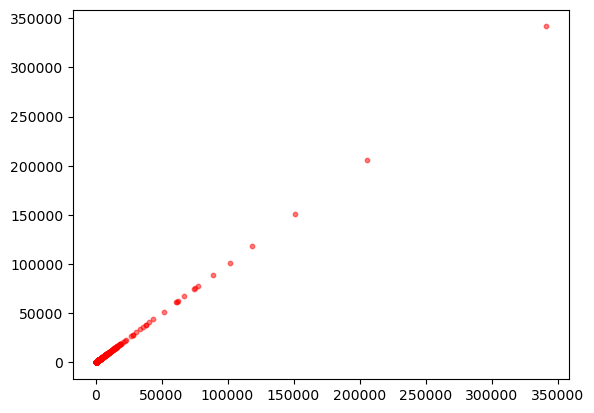

In [ ]:
import matplotlib.pyplot as plt

x = flat_out_data_yeast['BF_21']
y = jeff_out_data_yeast['BF_21']
colors = 'r'
area = 10

plt.scatter(x, y, s=area, c=colors, alpha=0.5)
plt.show()

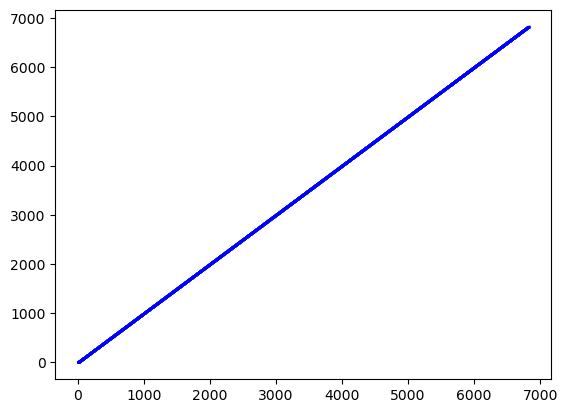

In [ ]:
# 

x = flat_out_data_yeast.BF_rank
y = jeff_out_data_yeast.BF_rank
colors = 'b'
area = 1

plt.scatter(x, y, s=area, c=colors, alpha=0.5)
plt.show()